In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


In [2]:
dataset=pd.read_csv('cooling_experiment.csv')
x=dataset.iloc[:,:-1].values
y=dataset.iloc[:,-1].values

In [3]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=1)

In [4]:
imputer_number = SimpleImputer(missing_values=np.nan, strategy='mean')
x_train[:, 1:3]=imputer_number.fit_transform(x_train[:, 1:3])
x_test[:, 1:3]=imputer_number. transform(x_test[:, 1:3])

imputer_letter = SimpleImputer(
    missing_values=np.nan, strategy='most_frequent')
x_train[:, 0:1]=imputer_letter.fit_transform(x_train[:, 0:1])
x_test[:, 0:1]=imputer_letter.transform(x_test[:, 0:1])


In [5]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(
    handle_unknown='ignore'), [0])], remainder='passthrough')
x_train = ct.fit_transform(x_train)
x_test = ct.transform(x_test)
print(x_train)

[[0.0 0.0 1.0 741.9203085006955 9.585357193023286]
 [0.0 0.0 1.0 390.8826388186797 1.3234804641706788]
 [0.0 1.0 0.0 988.1982429404655 8.6430106944476]
 [0.0 1.0 0.0 106.25691747807164 7.31770189531933]
 [0.0 1.0 0.0 670.0633808593811 8.8963576473516]
 [0.0 0.0 1.0 592.0392514089517 8.983777818386056]
 [0.0 0.0 1.0 905.344615384884 9.086987696743714]
 [1.0 0.0 0.0 633.1731119758382 9.43056989863061]
 [0.0 1.0 0.0 638.1099809299766 6.457861536936309]
 [0.0 1.0 0.0 305.9183489424602 6.1305505308042845]
 [0.0 1.0 0.0 936.7278871083156 5.808402973738373]
 [0.0 1.0 0.0 572.280788469014 2.678666593598688]
 [0.0 0.0 1.0 585.4080177240857 3.64232659838044]
 [1.0 0.0 0.0 557.7136220482325 3.852298046406499]
 [0.0 1.0 0.0 140.70456001948426 1.0455542546159682]
 [0.0 1.0 0.0 903.30309864098 4.2354203609777965]
 [0.0 0.0 1.0 488.7505167779042 1.3669762739928752]
 [1.0 0.0 0.0 240.41677639819287 9.870854086995406]
 [1.0 0.0 0.0 696.2700559185838 4.142886171513948]
 [0.0 1.0 0.0 392.7972976869379 2.

In [6]:
sc_X = StandardScaler()
sc_y = StandardScaler()
x_train[:, -2:] = sc_X.fit_transform(x_train[:, -2:])
x_test[:, -2:] = sc_X.transform(x_test[:, -2:])
print(x_train)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)
y_train = sc_y.fit_transform(y_train)
y_test= sc_y.transform(y_test)
print(y_train)

[[0.0 0.0 1.0 0.7379355130137757 1.5197231643934863]
 [0.0 0.0 1.0 -0.6114203223316692 -1.804586508753136]
 [0.0 1.0 0.0 1.6846047643626483 1.1405536750048375]
 [0.0 1.0 0.0 -1.7054948651813142 0.6072926490369155]
 [0.0 1.0 0.0 0.46172423144210356 1.2424922240586858]
 [0.0 0.0 1.0 0.1618068052950626 1.2776672490240284]
 [0.0 0.0 1.0 1.3661232010508413 1.3191955371175133]
 [1.0 0.0 0.0 0.3199215023202911 1.4574418066684567]
 [0.0 1.0 0.0 0.3388983629450689 0.2613209389105286]
 [0.0 1.0 0.0 -0.9380150733859097 0.12962166772530556]
 [0.0 1.0 0.0 1.4867575502664223 3.5737402154380187e-16]
 [0.0 1.0 0.0 0.08585712932549389 -1.2593038197438902]
 [0.0 0.0 1.0 0.13631696576781568 -0.8715584707564097]
 [1.0 0.0 0.0 0.029862309646639388 -0.7870728098508192]
 [0.0 1.0 0.0 -1.5730813623248985 -1.9164149488480067]
 [0.0 1.0 0.0 1.3582758024117219 -0.6329168888504625]
 [0.0 0.0 1.0 -0.23522539049777383 -1.7870852138199504]
 [1.0 0.0 0.0 -1.1897969668133954 1.6345978009237556]
 [1.0 0.0 0.0 0.5624602

In [7]:
from sklearn.svm import SVR 
regressor= SVR(kernel='rbf')
regressor.fit(x_train, y_train.ravel())

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


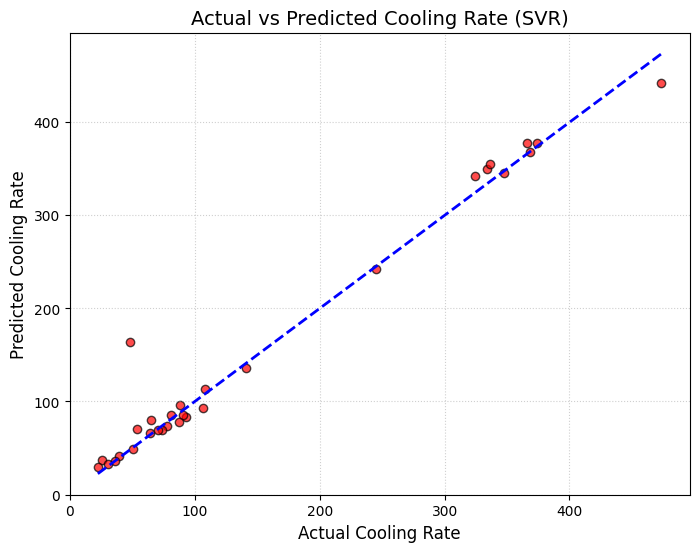

In [8]:
y_pred_scaled = regressor.predict(x_test)
y_pred_real = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1))

y_test_real = sc_y.inverse_transform(y_test.reshape(-1, 1))
plt.figure(figsize=(8, 6))
plt.scatter(y_test_real, y_pred_real, color='red', alpha=0.7, edgecolors='k')

min_val = min(y_test_real.min(), y_pred_real.min())
max_val = max(y_test_real.max(), y_pred_real.max())
plt.plot([min_val, max_val], [min_val, max_val], color='blue', linewidth=2, linestyle='--')
plt.title('Actual vs Predicted Cooling Rate (SVR)', fontsize=14)
plt.xlabel('Actual Cooling Rate', fontsize=12)
plt.ylabel('Predicted Cooling Rate', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

